<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# 4. Modellierung
Beschreibung dies das,
was wird gemacht usw,
was wird verwendet,
warum EDA notwendig war

log_prices nicht in workspace: lade Rohdaten und berechne Pivot (kann länger dauern)...
Anzahl Zeilen gesamt: 6,501,892
Anzahl Ticker gesamt: 506
Anzahl Handelstage: 34
Pivot erstellt: 12934 Zeitpunkte x 506 Symbole
`top_pairs` nicht gefunden: berechne stark korrelierte Paare (als Ersatz) ...
Letzter Handelstag (intraday Daten verwendet): 2025-12-26

--- Paar: GOOG - GOOGL ---


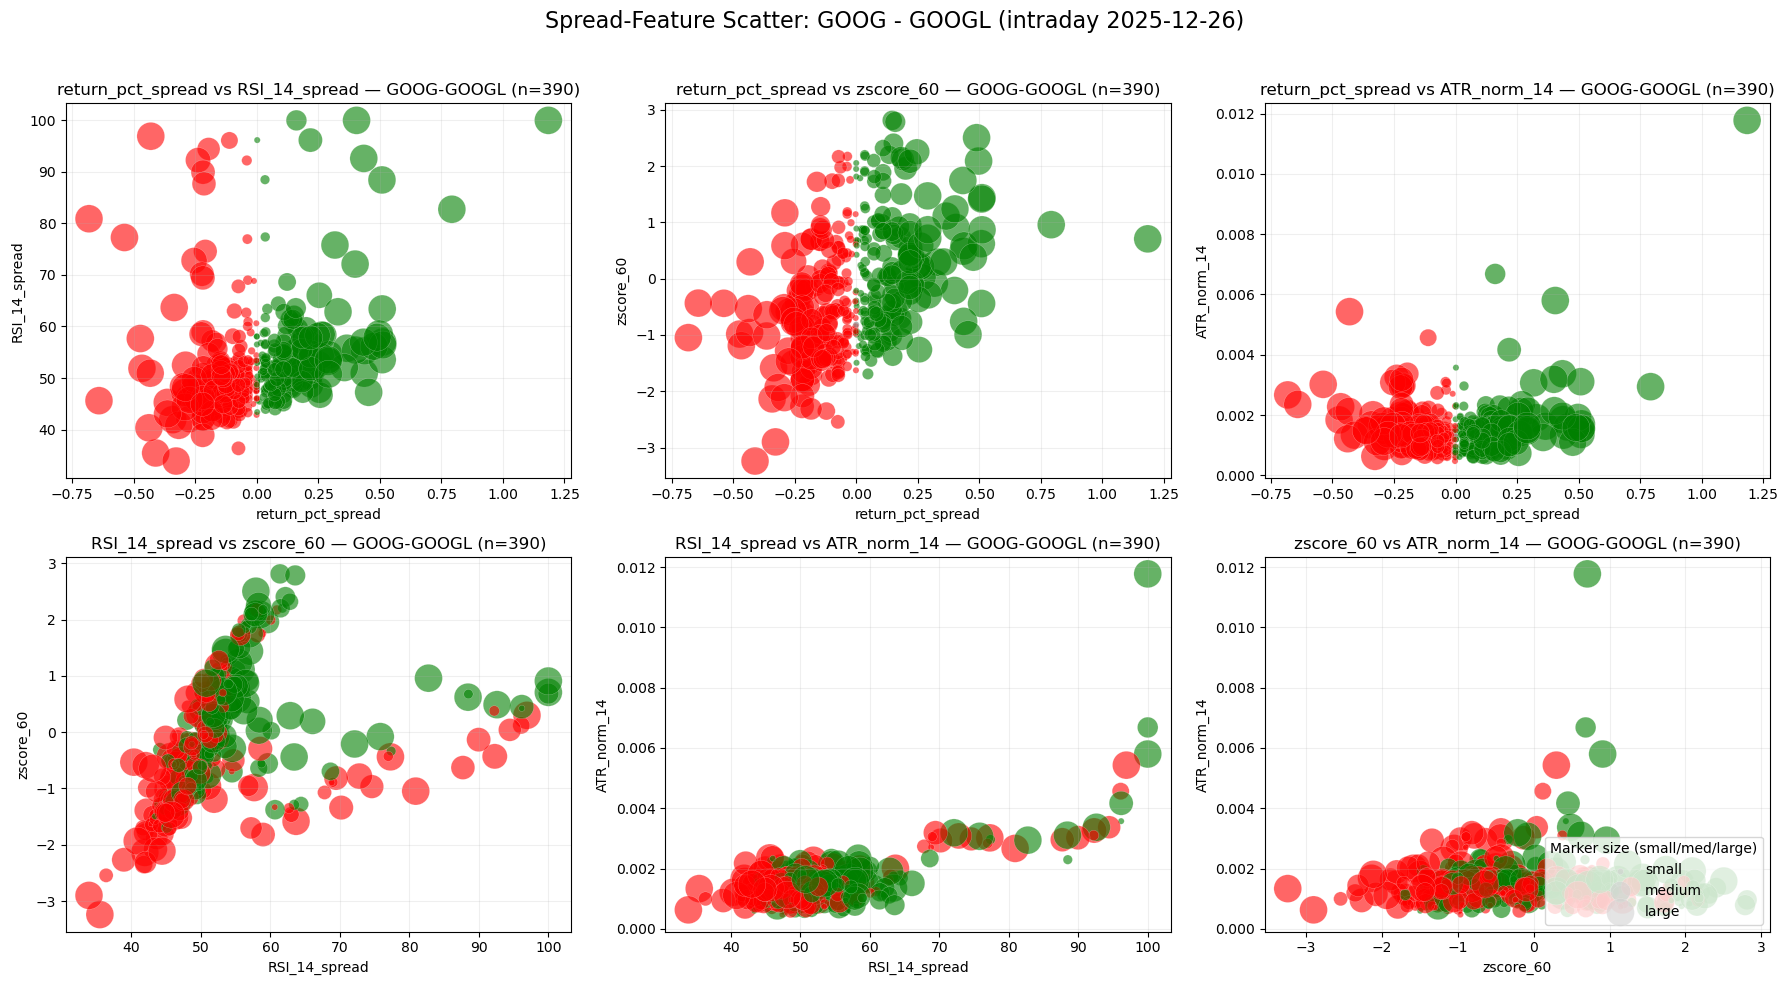


--- Paar: IPG - OMC ---
Nicht genügend Intraday-Daten für IPG-OMC am 2025-12-26 (gefunden: 0), überspringe.

--- Paar: CFG - USB ---


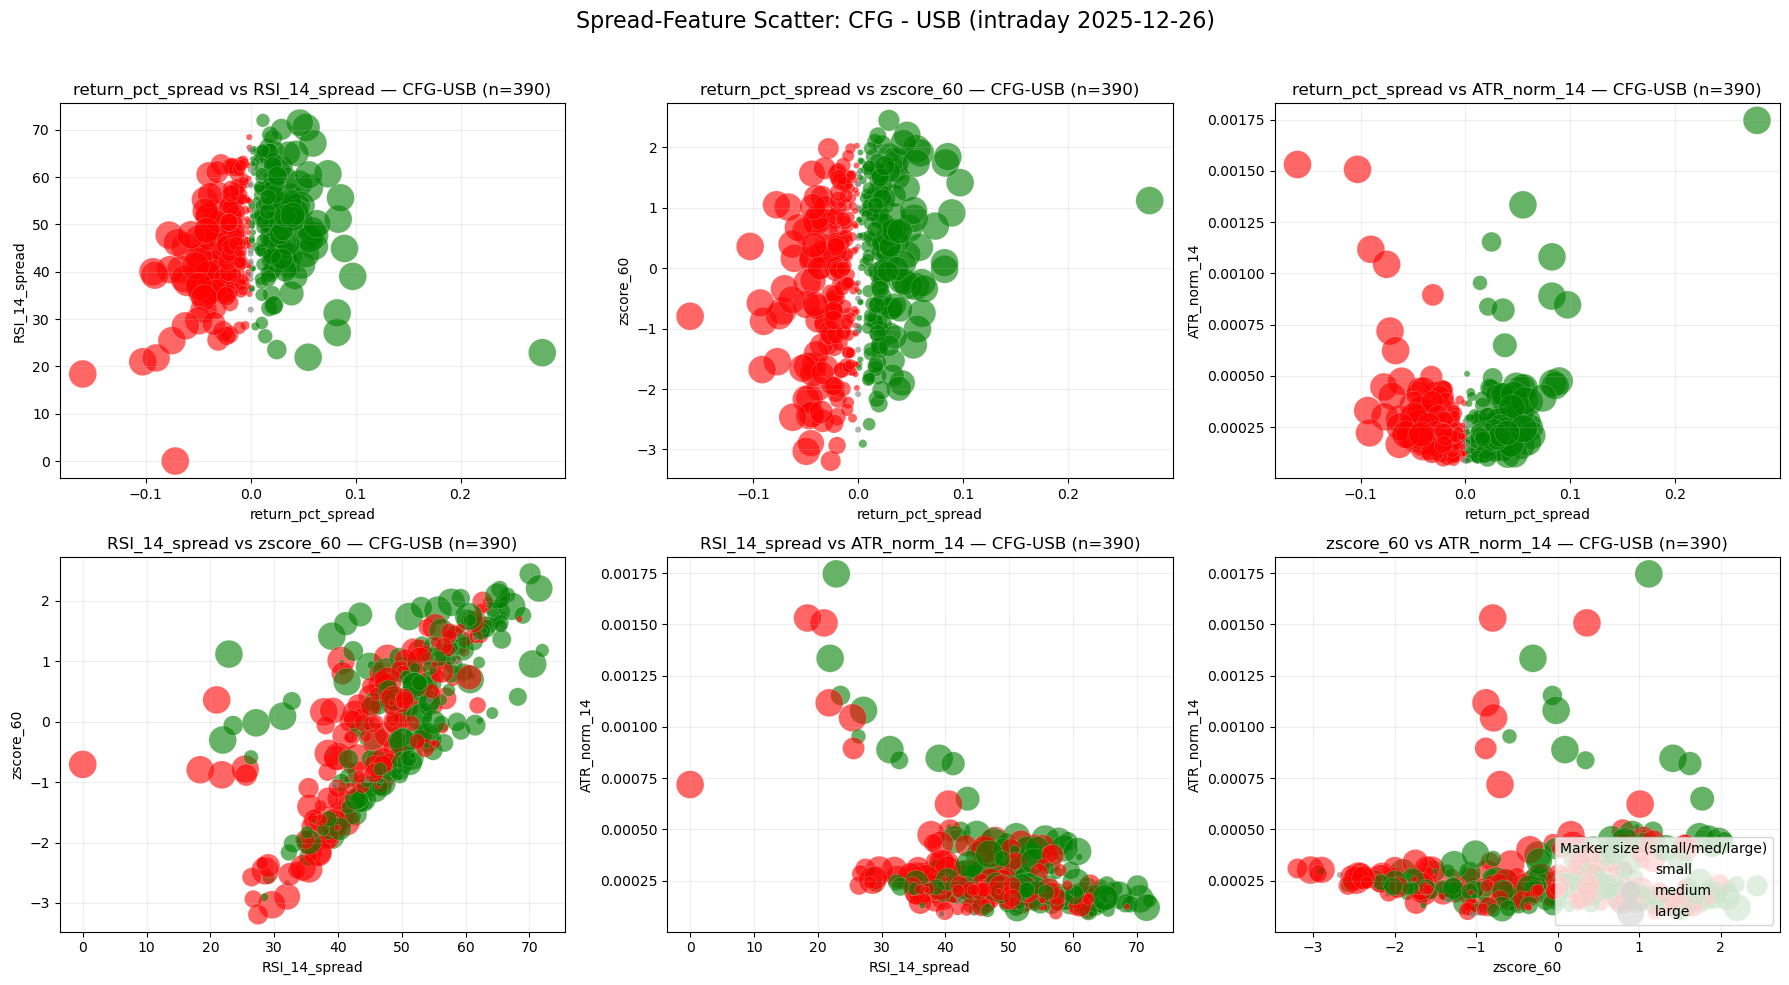


--- Paar: FITB - RF ---


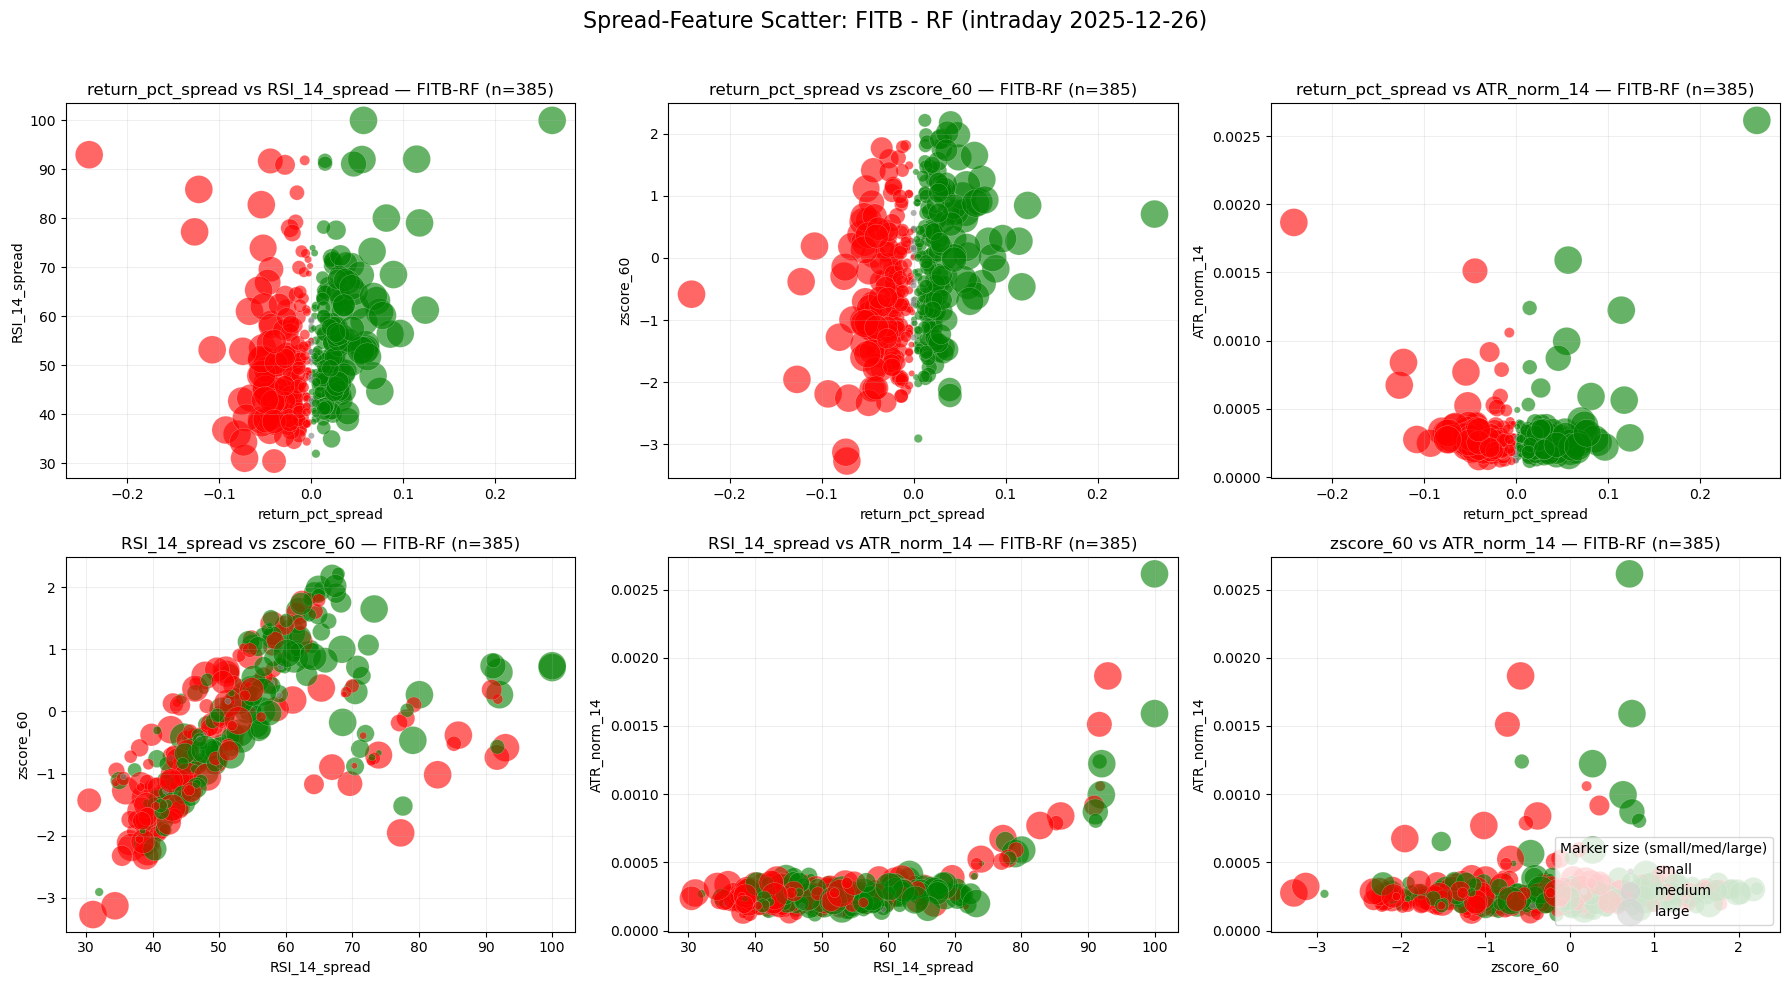


--- Paar: SYF - USB ---


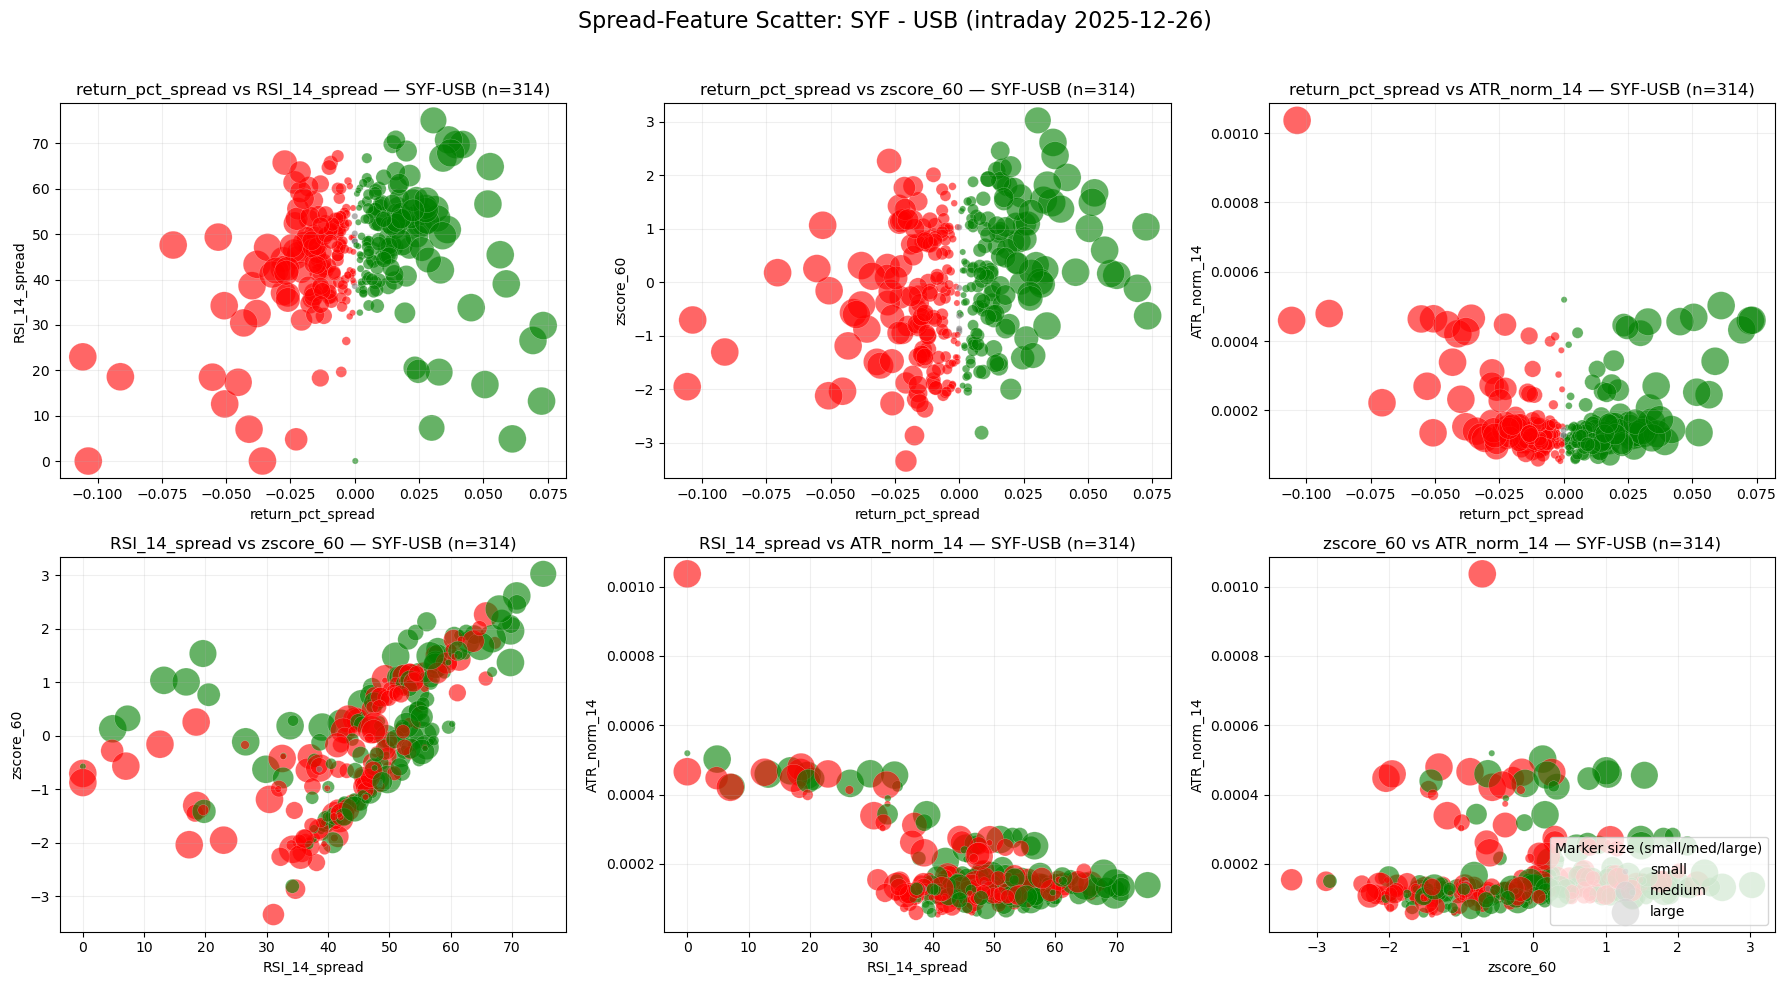


Fertig: Plots für alle Paare erstellt (falls Daten vorhanden).


In [4]:
# --- Spread-Feature Scatter-Matrix (Top-5 Paare, intraday letzter Handelstag) ---
# Lädt notwendige Hilfsfunktionen / Daten aus dem Projekt, berechnet falls nötig `log_prices` und `top_pairs`.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
from pathlib import Path

# Project helpers
from pairs_trading.eda.data_loading import fetch_data
from pairs_trading.eda.correlation import correlation_analysis

# ---- kleine Hilfsfunktionen ----
def compute_rsi(series, window=14):
    # Wilder-RSI (EMA basierend auf Wilder's smoothing)
    delta = series.diff()
    up = delta.clip(lower=0)
    down = -delta.clip(upper=0)
    # Wilder smoothing: alpha = 1/window (approx)
    ma_up = up.ewm(alpha=1/window, adjust=False).mean()
    ma_down = down.ewm(alpha=1/window, adjust=False).mean()
    rs = ma_up / ma_down
    return 100 - (100 / (1 + rs))

def compute_macd(series, fast=12, slow=26, signal=9):
    ema_fast = series.ewm(span=fast, adjust=False).mean()
    ema_slow = series.ewm(span=slow, adjust=False).mean()
    macd = ema_fast - ema_slow
    sig  = macd.ewm(span=signal, adjust=False).mean()
    hist = macd - sig
    return macd, sig, hist

# ---- Parameter ----
RSI_WINDOW = 14
ZSCORE_WINDOW = 60
ATR_WINDOW = 14
MIN_OBS_INTRADAY = 60
axis_features = ['return_pct_spread', 'RSI_14_spread', 'zscore_60', 'ATR_norm_14']

# ---- Daten / Vorbereitung ----
# 1) Falls `log_prices` nicht vorhanden, lade Rohdaten und erstelle Pivot (index=datetime, cols=symbols)
if 'log_prices' not in globals():
    print("log_prices nicht in workspace: lade Rohdaten und berechne Pivot (kann länger dauern)...")
    df_raw = fetch_data(data_dir="Daten", pattern="sp500_1min_*.csv")

    # Sicherstellen, dass datetime korrekt ist
    df_raw['datetime'] = pd.to_datetime(df_raw['datetime'], errors='coerce')
    df_raw = df_raw.dropna(subset=['datetime'])
    df_raw = df_raw.sort_values('datetime')

    prices_wide = df_raw.pivot_table(index='datetime', columns='symbol', values='close')
    # optional: optionally drop columns with too many NaNs
    log_prices = np.log(prices_wide)
    print(f"Pivot erstellt: {log_prices.shape[0]} Zeitpunkte x {log_prices.shape[1]} Symbole")
else:
    print("Verwende vorhandenes `log_prices` aus Workspace")

# 2) Falls `top_pairs` nicht vorhanden, erzeugen wir eine Liste starker Paare per Korrelationsanalyse
if 'top_pairs' not in globals():
    print("`top_pairs` nicht gefunden: berechne stark korrelierte Paare (als Ersatz) ...")
    corr_out = correlation_analysis(prices_wide=log_prices, method='pearson', strong_threshold=0.97, plot=False)
    strong_pairs = corr_out.get('strong_pairs')
    if strong_pairs is None or strong_pairs.empty:
        raise RuntimeError("Keine starken Paare gefunden — bitte erzeuge `top_pairs` vorher oder passe die Methode.")
    # Normiertes Format: symbol1, symbol2
    top_pairs = strong_pairs.rename(columns={'symbol_1': 'symbol1', 'symbol_2': 'symbol2'})
else:
    print("Verwende vorhandenes `top_pairs` aus Workspace")

# Nur Top-5
pairs = top_pairs.head(5)[['symbol1', 'symbol2']].values
if len(pairs) == 0:
    raise ValueError("Keine Paare gefunden in `top_pairs`")

# Letzter Handelstag (intraday)
last_day = log_prices.index.normalize().max()
print(f"Letzter Handelstag (intraday Daten verwendet): {last_day.date()}")

# ---- Haupt-Loop: für jedes Paar Spread + Features berechnen und Scatter-Matrix plotten ----
for s1, s2 in pairs:
    print('\n--- Paar:', s1, '-', s2, '---')
    # Extract intraday log prices for last day
    day_mask = log_prices.index.normalize() == last_day
    day_prices = log_prices.loc[day_mask, [s1, s2]].dropna()

    if day_prices.empty or len(day_prices) < MIN_OBS_INTRADAY:
        print(f"Nicht genügend Intraday-Daten für {s1}-{s2} am {last_day.date()} (gefunden: {len(day_prices)}), überspringe.")
        continue

    try:
        beta, intercept = np.polyfit(day_prices[s2].values, day_prices[s1].values, deg=1)
    except Exception as e:
        print(f"Fehler bei Beta-Berechnung für {s1}-{s2}: {e}")
        continue

    spread = day_prices[s1] - beta * day_prices[s2]
    spread.name = 'spread'
    df_sp = pd.DataFrame({'spread': spread})

    # 1) Log-return of spread
    df_sp['log_return_spread'] = df_sp['spread'].diff()

    # 2) Percent change vs previous (in %)
    prev_abs = df_sp['spread'].shift(1).abs()
    df_sp['return_pct_spread'] = (df_sp['spread'] - df_sp['spread'].shift(1)) / prev_abs * 100

    # 3) RSI & MACD hist
    df_sp['RSI_14_spread'] = compute_rsi(df_sp['spread'].fillna(method='ffill'), window=RSI_WINDOW)
    df_sp['RSI_delta_spread'] = df_sp['RSI_14_spread'] - df_sp['RSI_14_spread'].shift(1)
    df_sp['ROC_5_spread'] = df_sp['spread'].pct_change(5) * 100
    _macd, _macd_sig, df_sp['MACD_hist_spread'] = compute_macd(df_sp['spread'].fillna(method='ffill'))

    # 4) Rolling mean & std for zscore
    df_sp['roll_mean_60'] = df_sp['spread'].rolling(window=ZSCORE_WINDOW, min_periods=1).mean()
    df_sp['roll_std_60'] = df_sp['spread'].rolling(window=ZSCORE_WINDOW, min_periods=1).std()
    df_sp['zscore_60'] = (df_sp['spread'] - df_sp['roll_mean_60']) / df_sp['roll_std_60'].replace(0, np.nan)

    # 5) ATR-like
    df_sp['ATR_14_spread'] = df_sp['spread'].diff().abs().rolling(window=ATR_WINDOW, min_periods=1).mean()
    df_sp['ATR_norm_14'] = df_sp['ATR_14_spread'] / df_sp['roll_mean_60'].replace(0, np.nan)

    # Direction & marker sizes
    spread_prev = df_sp['spread'].shift(1)
    df_sp['dir'] = np.where(df_sp['spread'] > spread_prev, 'up', np.where(df_sp['spread'] < spread_prev, 'down', 'flat'))

    abs_pct = df_sp['return_pct_spread'].abs().fillna(0)
    scale = np.nanpercentile(abs_pct, 90)
    scale = scale if scale > 0 else (abs_pct.max() if abs_pct.max() > 0 else 1.0)
    min_size, max_size = 20, 400
    df_sp['marker_size'] = np.clip((abs_pct / scale) * max_size, min_size, max_size)

    color_map = {'up': 'green', 'down': 'red', 'flat': 'gray'}

    finite_mask = df_sp[axis_features].apply(lambda col: np.isfinite(col)).all(axis=1)
    plot_df = df_sp[finite_mask].copy()
    if plot_df.empty:
        print(f"Keine vollständigen Punkte zum Plotten für {s1}-{s2}. Skipping.")
        continue

    combs = list(itertools.combinations(axis_features, 2))
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for ax, (fx, fy) in zip(axes, combs):
        x = plot_df[fx]
        y = plot_df[fy]
        sz = plot_df['marker_size']
        c = plot_df['dir'].map(color_map)
        ax.scatter(x, y, s=sz, c=c, alpha=0.6, edgecolors='w', linewidth=0.2)
        ax.set_xlabel(fx)
        ax.set_ylabel(fy)
        ax.grid(alpha=0.2)
        ax.set_title(f"{fx} vs {fy} — {s1}-{s2} (n={len(plot_df)})")

    # Color legend (once)
    from matplotlib.lines import Line2D
    legend_elements = [Line2D([0], [0], marker='o', color='w', label='up (green)', markerfacecolor='green', markersize=10),
Line2D([0], [0], marker='o', color='w', label='down (red)', markerfacecolor='red', markersize=10),
Line2D([0], [0], marker='o', color='w', label='flat', markerfacecolor='gray', markersize=10)]
    axes[-1].legend(handles=legend_elements, title='Spread Direction', loc='upper right')

    # Size legend (representative sizes)
    rep_sizes = [min_size, int((min_size + max_size) / 2), max_size]
    for s, lbl in zip(rep_sizes, ['small', 'medium', 'large']):
        axes[-1].scatter([], [], s=s, color='lightgray', alpha=0.6, edgecolors='w', linewidth=0.2, label=lbl)
    axes[-1].legend(title='Marker size (small/med/large)', loc='lower right')

    plt.suptitle(f"Spread-Feature Scatter: {s1} - {s2} (intraday {last_day.date()})", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

print('\nFertig: Plots für alle Paare erstellt (falls Daten vorhanden).')

In [5]:
# --- KNN Decision Boundary Analysis per Paar (an Projektstruktur angepasst) ---

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Optionales Plot-Tool (komfortabler Entscheidungsgrenzen-Plot)
try:
    from mlxtend.plotting import plot_decision_regions
    HAS_MLEXT = True
except Exception:
    HAS_MLEXT = False

# ---------------- Konfiguration ----------------
LOOKAHEAD_MINUTES = 2   # Prognosehorizont fuer das Target
K_NEIGHBORS = 4         # Anzahl Nachbarn fuer KNN

# Feature-Kombinationen fuer 2D-Plots
selected_combs = list(itertools.combinations(axis_features, 2))[:6]

# =========================================================
# HAUPTSCHLEIFE: pro Paar komplette Datenaufbereitung
# =========================================================
pairs = pairs[:5]

all_plot_df = []

for s1, s2 in pairs:

    day_mask = log_prices.index.normalize() == last_day
    day_prices = log_prices.loc[day_mask, [s1, s2]].dropna()

    if day_prices.empty or len(day_prices) < MIN_OBS_INTRADAY:
        continue

    try:
        beta, _ = np.polyfit(day_prices[s2].values, day_prices[s1].values, 1)
    except Exception:
        continue

    spread = day_prices[s1] - beta * day_prices[s2]
    df_sp = pd.DataFrame({'spread': spread})

    # --- Feature Engineering ---
    df_sp['log_return_spread'] = df_sp['spread'].diff()
    prev_abs = df_sp['spread'].shift(1).abs()
    df_sp['return_pct_spread'] = (df_sp['spread'] - df_sp['spread'].shift(1)) / prev_abs * 100
    df_sp['RSI_14_spread'] = compute_rsi(df_sp['spread'].ffill(), RSI_WINDOW)

    df_sp['roll_mean_60'] = df_sp['spread'].rolling(ZSCORE_WINDOW, 1).mean()
    df_sp['roll_std_60'] = df_sp['spread'].rolling(ZSCORE_WINDOW, 1).std()
    df_sp['zscore_60'] = (df_sp['spread'] - df_sp['roll_mean_60']) / df_sp['roll_std_60'].replace(0, np.nan)

    df_sp['ATR_14_spread'] = df_sp['spread'].diff().abs().rolling(ATR_WINDOW, 1).mean()
    df_sp['ATR_norm_14'] = df_sp['ATR_14_spread'] / df_sp['roll_mean_60'].replace(0, np.nan)

    df_sp['future_return'] = df_sp['spread'].shift(-LOOKAHEAD_MINUTES) - df_sp['spread']
    df_sp['target'] = (df_sp['future_return'] > 0).astype(int)

    finite = df_sp[axis_features + ['future_return', 'target']].apply(np.isfinite).all(axis=1)
    df_sp = df_sp[finite]

    if not df_sp.empty:
        all_plot_df.append(df_sp)

# =========================================================
# 2) GEMEINSAMES DATAFRAME
# =========================================================

all_plot_df = pd.concat(all_plot_df, axis=0)

print(f"Gesammelte Beobachtungen: {len(all_plot_df)}")


    # =====================================================
    # PRO FEATURE-KOMBINATION: KNN + PLOTS
    # =====================================================
for fx, fy in selected_combs:
        if fx not in plot_df.columns or fy not in plot_df.columns:
            continue

        #! Feature-Matrix (2D)
        X = plot_df[[fx, fy]].values

        #! Zielvariable
        y = plot_df['target'].values

        #! Standardisierung der Features
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)

        # KNN-Modell
        knn = KNeighborsClassifier(n_neighbors=K_NEIGHBORS)
        knn.fit(X_scaled, y)

        # Genauigkeit (nur zur Einordnung)
        y_pred = knn.predict(X_scaled)
        acc = accuracy_score(y, y_pred)

        # ================== PLOTS ==================
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

        #! Farben gemaess zukuenftiger Richtung
        colors = np.where(plot_df['future_return'] > 0, 'green', 'red')

        #! Marker-Groesse proportional zur Bewegungsstaerke
        size_scale = (
            500 / plot_df['future_return'].abs().max()
            if plot_df['future_return'].abs().max() != 0 else 1.0
        )
        sizes = plot_df['future_return'].abs() * size_scale + 20

        #! Scatterplot der Originaldaten
        ax1.scatter(
            X[:, 0], X[:, 1],
            s=sizes, c=colors, alpha=0.4,
            edgecolors='w', linewidth=0.3
        )
        ax1.set_xlabel(fx)
        ax1.set_ylabel(fy)
        ax1.set_title(f"Echtdaten: {fx} vs {fy} — {s1}-{s2}")
        ax1.grid(True, alpha=0.2)

        # Entscheidungsgrenzen (mlxtend oder Fallback)
        if HAS_MLEXT:
            try:
                plot_decision_regions(
                    X_scaled, y, clf=knn,
                    legend=2, ax=ax2,
                    colors='red,green', markers='ox'
                )
                ax2.set_title(f"KNN Grenzen (acc={acc:.2f}) — k={K_NEIGHBORS}")
            except Exception:
                HAS_MLEXT = False

        if not HAS_MLEXT:
            x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
            y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5
            xx, yy = np.meshgrid(
                np.linspace(x_min, x_max, 200),
                np.linspace(y_min, y_max, 200)
            )
            Z = knn.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
            ax2.contourf(xx, yy, Z, alpha=0.2, levels=[-0.5, 0.5, 1.5],
                         colors=['red', 'green'])
            ax2.scatter(
                X_scaled[:, 0], X_scaled[:, 1],
                c=np.where(y > 0, 'green', 'red'),
                s=20, alpha=0.6, edgecolors='w'
            )

        plt.suptitle(
            f"KNN Klassifikation: {s1}-{s2} | {fx} vs {fy} | T+{LOOKAHEAD_MINUTES}m",
            fontsize=14
        )
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()
print("Verwendete Paare:")
for s1, s2 in pairs:
    print(s1, s2)


print('\nFertig: KNN-Analysen für alle Paare abgeschlossen.')


Gesammelte Beobachtungen: 1471


KeyError: 'target'

In [4]:
import numpy as np
import pandas as pd
from typing import Literal
from pairs_trading.eda.spread_labels import classify_top_pair_spread,get_top_pairs_today
from IPython.display import display
import inspect
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)



print(get_top_pairs_today())
df_labels = classify_top_pair_spread(
    pair_rank=2,
    lookahead=2,
    feature_specs=[
        {"name": "SMA", "params": {"window": 20}},
        {"name": "RSI", "params": {"window": 14}},
        {"name": "MACD_HIST", "params": {"fast": 12, "slow": 26, "signal": 9}},
    ]
)
display(df_labels)




Anzahl Zeilen gesamt: 6,697,777
Anzahl Ticker gesamt: 506
Anzahl Handelstage: 35
[('GOOG', 'GOOGL'), ('NSC', 'UNP'), ('AEE', 'PPL'), ('TSCO', 'VRTX'), ('PSA', 'TSCO')]
Anzahl Zeilen gesamt: 6,697,777
Anzahl Ticker gesamt: 506
Anzahl Handelstage: 35
Anzahl Zeilen gesamt: 6,697,777
Anzahl Ticker gesamt: 506
Anzahl Handelstage: 35


,spread,SMA_AEE_20,SMA_PPL_20,RSI_AEE_14,RSI_PPL_14,MACD_HIST_AEE_12_26_9,MACD_HIST_PPL_12_26_9,future_spread,spread_change,spread_change_pct,dominant_stock,target_4c
datetime,,,,,,,,,,,,
2025-12-29 14:30:00,0.633614,NaN,NaN,NaN,NaN,0.000000e+00,0.000000e+00,0.631847,-0.001767,-0.278860,PPL,1
2025-12-29 14:31:00,0.633409,NaN,NaN,NaN,NaN,1.084184e-04,1.088754e-04,0.634596,0.001186,0.187319,AEE,2
2025-12-29 14:32:00,0.631847,NaN,NaN,NaN,NaN,7.478665e-05,1.747847e-04,0.632679,0.000832,0.131655,AEE,2
2025-12-29 14:33:00,0.634596,NaN,NaN,NaN,NaN,1.195301e-04,1.119494e-04,0.633484,-0.001112,-0.175286,PPL,1
2025-12-29 14:35:00,0.632679,NaN,NaN,NaN,NaN,8.536582e-06,7.127973e-05,0.634302,0.001623,0.256545,AEE,2
2025-12-29 14:39:00,0.633484,NaN,NaN,NaN,NaN,-1.927004e-04,-1.661799e-04,0.633231,-0.000252,-0.039837,PPL,1
2025-12-29 14:40:00,0.634302,NaN,NaN,NaN,NaN,-1.970770e-04,-2.172815e-04,0.632389,-0.001914,-0.301679,PPL,1
2025-12-29 14:42:00,0.633231,NaN,NaN,NaN,NaN,-1.511060e-04,-1.342178e-04,0.633390,0.000159,0.025085,AEE,2
2025-12-29 14:43:00,0.632389,NaN,NaN,NaN,NaN,-1.967113e-04,-1.047667e-04,0.632713,0.000325,0.051371,AEE,2


Anzahl Zeilen gesamt: 6,697,777
Anzahl Ticker gesamt: 506
Anzahl Handelstage: 35
  symbol1 symbol2  correlation
0    GOOG   GOOGL     0.992099


<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="03_Explorative_Datenanalyse.html">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="05_.html">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>
